**6-Regression Smart Fright**

Smart Fright EDA, Visualization and Model training

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("Module Imported")

Module Imported


In [2]:
df = pd.read_csv("/content/DataCoSupplyChainDataset.csv", encoding='latin1')
plt.style.use('ggplot')
print(f"Shape: {df.shape}")
df.head()

Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

creating df_clean so that any changes in df_clean does not affect the actual df(that can be used later)

In [4]:
df_clean = df.copy()

In [5]:
df_clean.drop("Product Description", axis=1, inplace=True)
df_clean.drop("Order Zipcode", axis=1, inplace=True)

In [6]:
print(f"{df_clean.duplicated().sum()}")

df_clean.drop_duplicates(inplace=True)

0


Removing unnecessary features in datasets

In [7]:
p_cols = [
    "Customer Email",
    "Customer Password",
    "Customer Fname",
    "Customer Lname",
    "Customer Street"
]

df_clean.drop(columns=p_cols, inplace=True)

In [8]:
id_cols = [
    "Customer Id",
    "Order Customer Id",
    "Order Id",
    "Order Item Id",
    "Category Id",
    "Department Id",
    "Product Card Id",
    "Order Item Cardprod Id",
    "Product Category Id"
]

df_clean.drop(columns=id_cols, inplace=True)

In [9]:
leakage_cols = [
    "Delivery Status",
    "shipping date (DateOrders)"
]

df_clean.drop(columns=leakage_cols, inplace=True)

Instead of storing the full timestamp

In [10]:
df_clean["order date (DateOrders)"] = pd.to_datetime(df_clean["order date (DateOrders)"], format='mixed', dayfirst=True)
df_clean["order_month"] = df_clean["order date (DateOrders)"].dt.month
df_clean["order_day"] = df_clean["order date (DateOrders)"].dt.day
df_clean["order_weekday"] = df_clean["order date (DateOrders)"].dt.weekday
df_clean["order_hour"] = df_clean["order date (DateOrders)"].dt.hour

df_clean["is_weekend"] = (
    df_clean["order_weekday"] >= 5
).astype(int)

In [11]:
df_clean.drop(
    "order date (DateOrders)",
    axis=1,
    inplace=True
)

Shipping patterns often depend on:
Month, Day of week, Order time, Weekend activity
These derived features help the model learn temporal trends.

In [12]:
df_clean.isnull().sum().sort_values(ascending=False)

,0
Customer Zipcode,3
Days for shipping (real),0
Type,0
Benefit per order,0
Sales per customer,0
Late_delivery_risk,0
Days for shipment (scheduled),0
Category Name,0
Customer City,0
Customer Segment,0


In [13]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 39 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Late_delivery_risk             180519 non-null  int64  
 6   Category Name                  180519 non-null  object 
 7   Customer City                  180519 non-null  object 
 8   Customer Country               180519 non-null  object 
 9   Customer Segment               180519 non-null  object 
 10  Customer State                 180519 non-null  object 
 11  Customer Zipcode               180516 non-null  float64
 12  Department Name               

In [14]:
df_clean.drop("Customer Zipcode", axis=1, inplace=True)

In [15]:
df_clean.drop("Product Image", axis=1, inplace=True)

In [16]:
df_clean["Product Status"].value_counts()
df_clean["Product Status"].nunique()

1

In [17]:
df_clean.drop("Product Status", axis=1, inplace=True)

In [18]:
print(df_clean.shape)

print(df_clean["Product Name"].nunique())

print(df_clean["Order City"].nunique())

print(
    (df_clean["Product Price"] ==
     df_clean["Order Item Product Price"]).all()
)

(180519, 36)
118
3597
True


In [19]:
df_clean.drop(
    "Order Item Product Price",
    axis=1,
    inplace=True
)

Removed: Customer Zipcode,
Product Image,
Product Status

These variables either:

Contain little useful information,
Have excessive uniqueness,
Do not influence shipping duration

In [20]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 35 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Late_delivery_risk             180519 non-null  int64  
 6   Category Name                  180519 non-null  object 
 7   Customer City                  180519 non-null  object 
 8   Customer Country               180519 non-null  object 
 9   Customer Segment               180519 non-null  object 
 10  Customer State                 180519 non-null  object 
 11  Department Name                180519 non-null  object 
 12  Latitude                      

Saving clean data file into new csv file

In [21]:
df_clean.to_csv(
    "DataCo_Cleaned.csv",
    index=False
)

Visualizing cleaned dataset

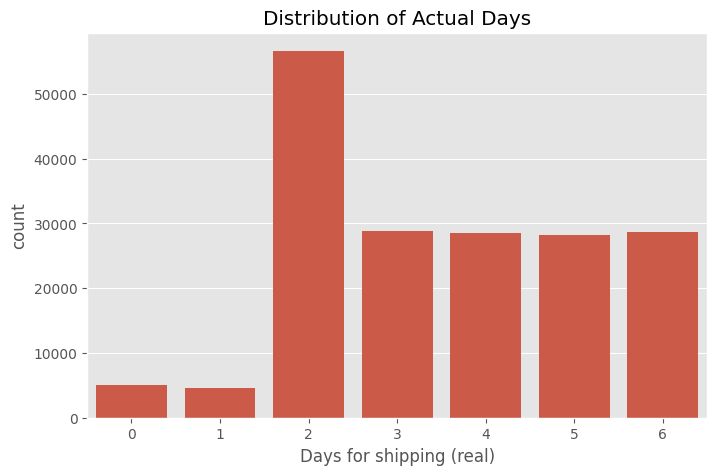

In [22]:
plt.figure(figsize=(8,5))
sns.countplot(
    data = df_clean,
    x = 'Days for shipping (real)'
)

plt.title("Distribution of Actual Days")
plt.show()

Insights:

Majority of orders required 2 days for shipping and also distribution is lowest for 1 day and same day order.

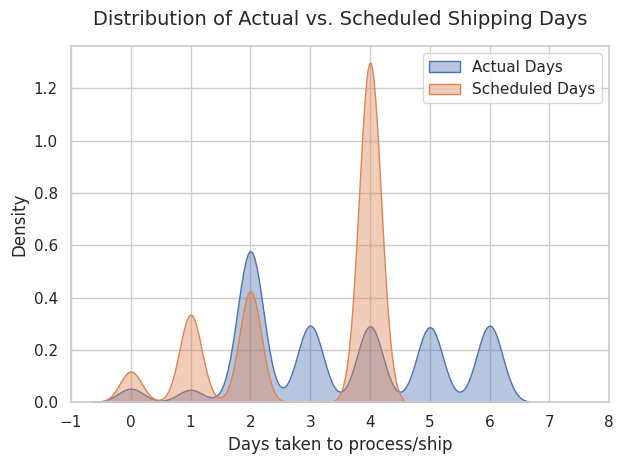

In [23]:
sns.set_theme(style="whitegrid")

# Plotting Kernel Density Estimation (KDE)
sns.kdeplot(df_clean['Days for shipping (real)'], label='Actual Days', fill=True, alpha=0.4, bw_adjust=1.5)
sns.kdeplot(df_clean['Days for shipment (scheduled)'], label='Scheduled Days', fill=True, alpha=0.4, bw_adjust=1.5)

plt.title('Distribution of Actual vs. Scheduled Shipping Days', fontsize=14, pad=15)
plt.xlabel('Days taken to process/ship', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.xlim(-1, 8)
plt.legend(fontsize=11)

plt.tight_layout()

Orders with longer scheduled durations generally experience longer actual delivery durations.

This suggests scheduled shipping days are a strong predictor.

<Axes: xlabel='Shipping Mode', ylabel='Days for shipping (real)'>

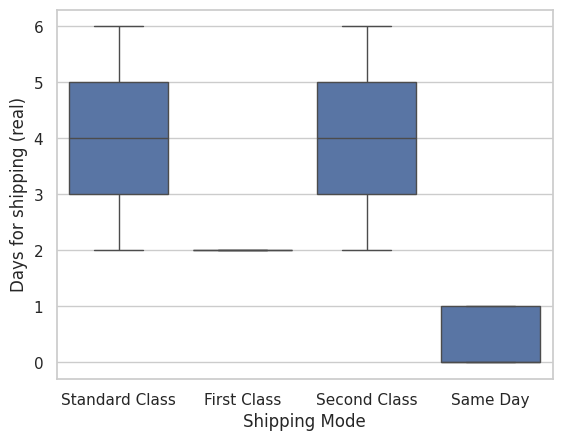

In [24]:
sns.boxplot(
    x='Shipping Mode',
    y = 'Days for shipping (real)',
    data = df_clean
)

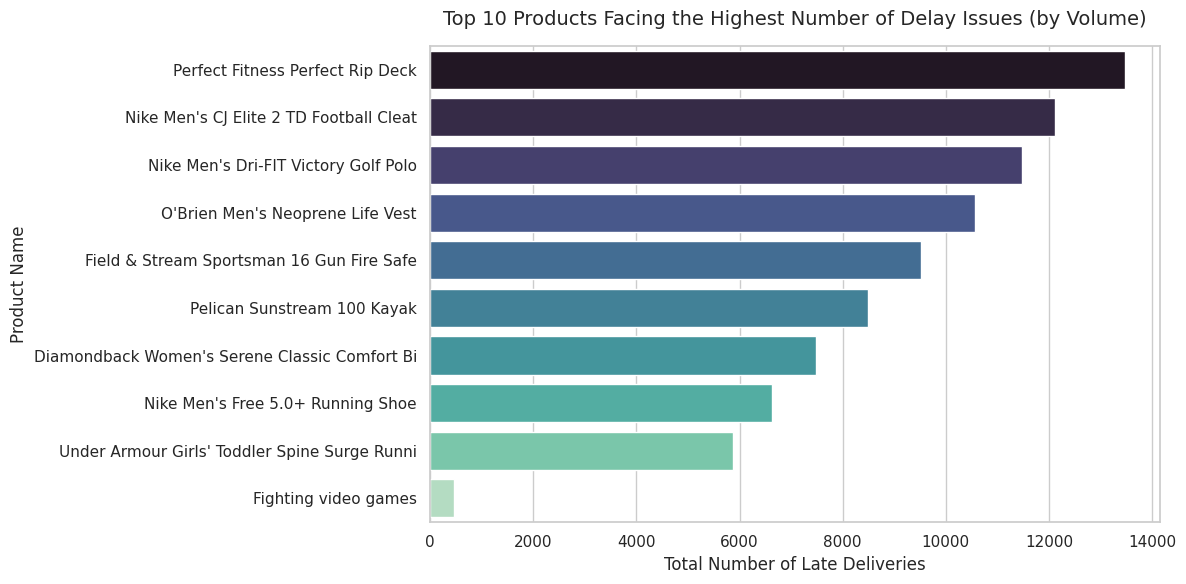

In [25]:
top_late_products = df[df['Late_delivery_risk'] == 1]['Product Name'].value_counts().reset_index()
top_late_products.columns = ['Product Name', 'Late Deliveries Count']
top_late_products = top_late_products.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x='Late Deliveries Count', y='Product Name', data=top_late_products, palette='mako', hue='Product Name', legend=False)

plt.title('Top 10 Products Facing the Highest Number of Delay Issues (by Volume)', fontsize=14, pad=15)
plt.xlabel('Total Number of Late Deliveries', fontsize=12)
plt.ylabel('Product Name', fontsize=12)

plt.tight_layout()
plt.show()

It shows total delayed deliveries fr top 10 products.

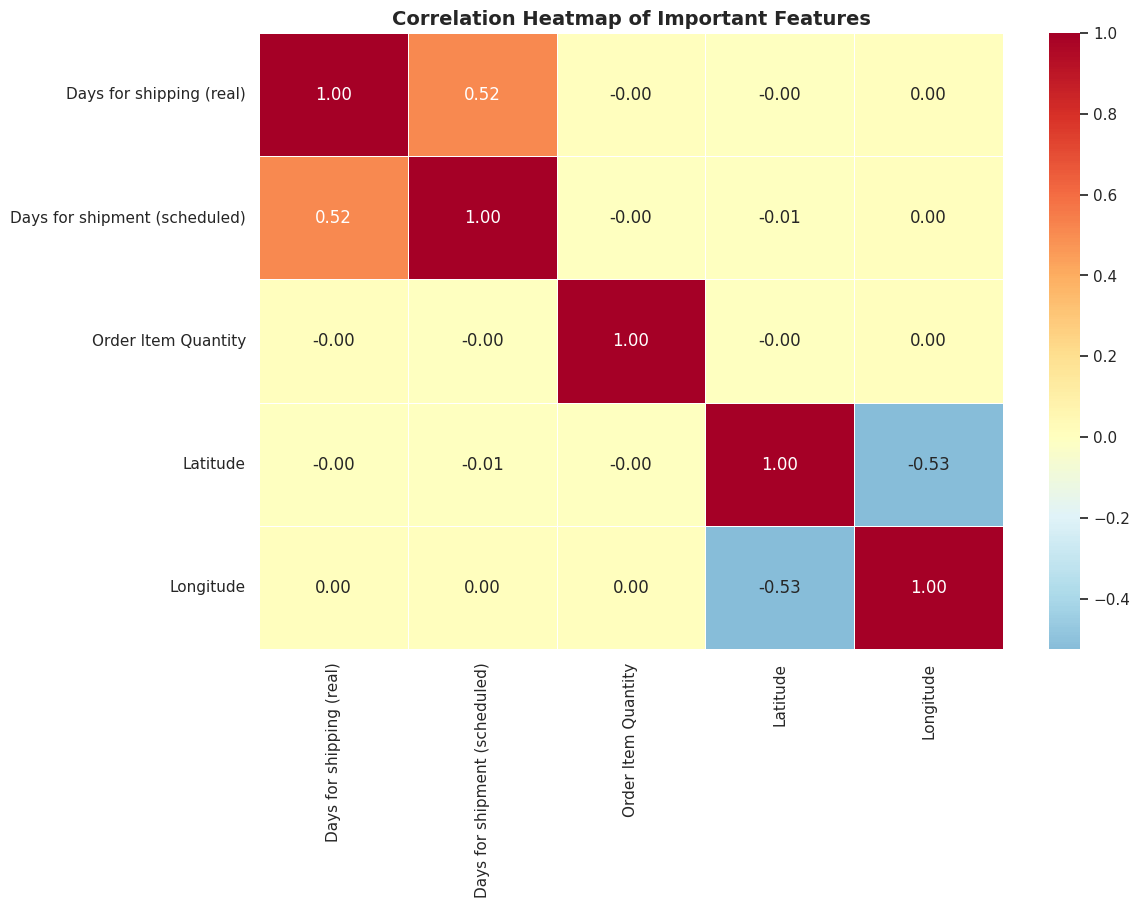

In [26]:
important_num = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Order Item Quantity",
    "Latitude",
    "Longitude",
]

corr_matrix = df_clean[important_num].corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap of Important Features",
    fontsize=14,
    fontweight='bold'
)

plt.show()

It shows high positive correlation of actual shipping days and scheduled shipping days.

Also latitude and longitude are less related with actual shipping days.

In [27]:
df_clean["Shipping delays"] = (
    df_clean["Days for shipping (real)"] -
    df_clean["Days for shipment (scheduled)"]
)

In [28]:
df_clean.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Late_delivery_risk',
       'Category Name', 'Customer City', 'Customer Country',
       'Customer Segment', 'Customer State', 'Department Name', 'Latitude',
       'Longitude', 'Market', 'Order City', 'Order Country',
       'Order Item Discount', 'Order Item Discount Rate',
       'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
       'Order Item Total', 'Order Profit Per Order', 'Order Region',
       'Order State', 'Order Status', 'Product Name', 'Product Price',
       'Shipping Mode', 'order_month', 'order_day', 'order_weekday',
       'order_hour', 'is_weekend', 'Shipping delays'],
      dtype='object')

In [29]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 36 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Late_delivery_risk             180519 non-null  int64  
 6   Category Name                  180519 non-null  object 
 7   Customer City                  180519 non-null  object 
 8   Customer Country               180519 non-null  object 
 9   Customer Segment               180519 non-null  object 
 10  Customer State                 180519 non-null  object 
 11  Department Name                180519 non-null  object 
 12  Latitude                      

As most of the Independant variables are categorical, using Decision Tree

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

target_col = 'Days for shipping (real)'

feature_cols = [
    'Days for shipment (scheduled)', 'Shipping Mode', 'order_month',
    'order_day', 'order_weekday', 'order_hour', 'is_weekend',
    'Latitude', 'Longitude', 'Market', 'Order Region', 'Order Country',
    'Order State', 'Order City', 'Customer Country', 'Customer State',
    'Customer City', 'Category Name', 'Department Name', 'Product Name',
    'Order Item Quantity', 'Sales', 'Order Item Total', 'Product Price',
    'Order Item Discount', 'Type', 'Customer Segment'
]

In [31]:
X = df_clean[feature_cols].copy()
y = df_clean[target_col].copy()

Feature Transformation

In [32]:
label_encoders = {}
for col in X.columns:
    if X[col].dtype == 'object':
        le = LabelEncoder()
        # Convert to string to handle any hidden NaN values gracefully
        X[col] = le.fit_transform(X[col].astype(str))
        label_encoders[col] = le # Store the encoder in case we need to decode later

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
dt_model = DecisionTreeRegressor(max_depth=20, random_state=42)
print("Training the Decision Tree...")
dt_model.fit(X_train, y_train)
print("Training Complete!")

Training the Decision Tree...
Training Complete!


In [34]:
y_pred = dt_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n--- Model Evaluation ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} days")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} days")


--- Model Evaluation ---
Mean Absolute Error (MAE): 0.86 days
Root Mean Squared Error (RMSE): 1.20 days


In [35]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop 5 Most Important Features:")
print(feature_importance.head(5))


Top 5 Most Important Features:
                         Feature  Importance
1                  Shipping Mode    0.703682
0  Days for shipment (scheduled)    0.070412
5                     order_hour    0.030297
7                       Latitude    0.028967
8                      Longitude    0.025393


In [36]:
from sklearn.metrics import r2_score

# Calculate R-Squared
r2 = r2_score(y_test, y_pred)

print(f"R-Squared (Accuracy Equivalent): {r2:.4f}")
print(f"This means the model explains {r2 * 100:.2f}% of the variance in actual shipping days.")

R-Squared (Accuracy Equivalent): 0.4554
This means the model explains 45.54% of the variance in actual shipping days.


Using random forest

In [37]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest
# n_estimators=100 means it builds 100 different trees
# max_depth=15 gives it enough depth to learn, but the ensemble prevents memorization
rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)

print("Training the Random Forest...")
rf_model.fit(X_train, y_train)
print("Training Complete!")

# Make Predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("\n--- Random Forest Evaluation ---")
print(f"Mean Absolute Error (MAE): {mae_rf:.2f} days")
print(f"Root Mean Squared Error (RMSE): {rmse_rf:.2f} days")
print(f"R-Squared: {r2_rf:.4f}")

Training the Random Forest...
Training Complete!

--- Random Forest Evaluation ---
Mean Absolute Error (MAE): 0.90 days
Root Mean Squared Error (RMSE): 1.19 days
R-Squared: 0.4640


Plotting confusion matrix

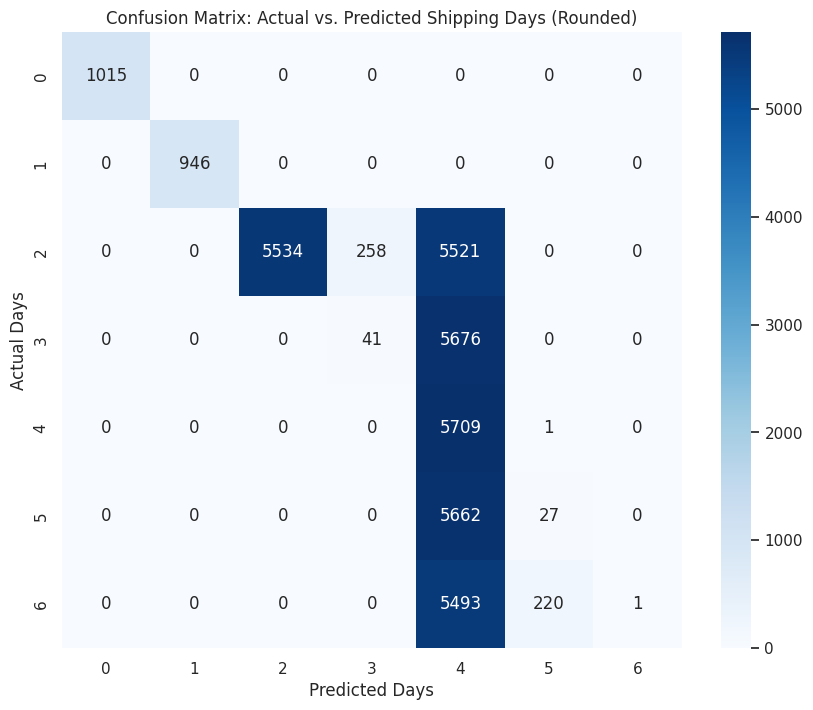

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Round predictions to the nearest integer for categorical comparison
y_pred_rf_rounded = np.round(y_pred_rf)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_rf_rounded)

# Plotting
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y_test.unique()),
            yticklabels=sorted(y_test.unique()))

plt.title('Confusion Matrix: Actual vs. Predicted Shipping Days (Rounded)')
plt.xlabel('Predicted Days')
plt.ylabel('Actual Days')
plt.show()

In [39]:
import xgboost as xgb
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define the Custom Business Logic (Asymmetric Loss)
def asymmetric_loss(y_true, y_pred):
    # Calculate how far off the prediction is
    residual = y_pred - y_true

    # Set the penalty multiplier for Late Deliveries (Prediction < Actual)
    penalty = 3.0

    # Gradient (1st derivative) and Hessian (2nd derivative)
    # If residual is negative (late), multiply the error by the penalty
    grad = np.where(residual < 0, penalty * residual, residual)
    hess = np.where(residual < 0, penalty * np.ones_like(residual), np.ones_like(residual))

    return grad, hess

# 2. Initialize XGBoost with our custom mathematical objective
print("Training the Business-Optimized XGBoost Model...")
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=8,              # Slightly shallower than RF to prevent overfitting
    learning_rate=0.1,
    objective=asymmetric_loss, # Injecting our custom penalty here
    random_state=42,
    n_jobs=-1
)

# 3. Train the Model
xgb_model.fit(X_train, y_train)
print("Training Complete!")

# 4. Make Predictions and Evaluate
y_pred_xgb = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("\n--- XGBoost Custom Evaluation ---")
print(f"Mean Absolute Error (MAE): {mae_xgb:.2f} days")
print(f"Root Mean Squared Error (RMSE): {rmse_xgb:.2f} days")
print(f"R-Squared: {r2_xgb:.4f}")

Training the Business-Optimized XGBoost Model...
Training Complete!

--- XGBoost Custom Evaluation ---
Mean Absolute Error (MAE): 1.00 days
Root Mean Squared Error (RMSE): 1.32 days
R-Squared: 0.3438


Using xgboost to find the features that contributes 95% in predictions, and then using them to do grid serach cv on new xgboost.

In [41]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Base Setup (Assuming df_clean is ready)
target_col = 'Days for shipping (real)'
feature_cols = [
    'Days for shipment (scheduled)', 'Shipping Mode', 'order_month',
    'order_day', 'order_weekday', 'order_hour', 'is_weekend',
    'Latitude', 'Longitude', 'Market', 'Order Region', 'Order Country',
    'Order State', 'Order City', 'Customer Country', 'Customer State',
    'Customer City', 'Category Name', 'Department Name', 'Product Name',
    'Order Item Quantity', 'Sales', 'Order Item Total', 'Product Price',
    'Order Item Discount', 'Type', 'Customer Segment'
]

X = df_clean[feature_cols].copy()
y = df_clean[target_col].copy()

# 2. Target Encoding (Must be done before checking importance)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

categorical_cols = X.select_dtypes(include=['object']).columns
for col in categorical_cols:
    means = y_train.groupby(X_train[col]).mean()
    X_train[col] = X_train[col].map(means)
    X_test[col] = X_test[col].map(means)
    global_mean = y_train.mean()
    X_train[col].fillna(global_mean, inplace=True)
    X_test[col].fillna(global_mean, inplace=True)

# 3. The "Scout" Model (Fast baseline to find what matters)
print("Training Scout XGBoost to analyze feature importance...")
scout_xgb = xgb.XGBRegressor(random_state=42, n_jobs=-1)
scout_xgb.fit(X_train, y_train)

# 4. Extract and Sort Feature Importances
importances = scout_xgb.feature_importances_
feature_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_df = feature_df.sort_values(by='Importance', ascending=False)
feature_df['Cumulative_Importance'] = feature_df['Importance'].cumsum()

print("\n--- Feature Importance Breakdown ---")
print(feature_df.head(15).to_string(index=False))

# 5. The Cut-Off (Keep only features that make up 98% of the predictive power)
top_features = feature_df[feature_df['Cumulative_Importance'] <= 0.98]['Feature'].tolist()

# Ensure we have at least 5 features just in case the top 2 dominate completely
if len(top_features) < 5:
    top_features = feature_df['Feature'].head(5).tolist()

print(f"\n[ACTION] Reducing dataset from {len(feature_cols)} features down to {len(top_features)} critical features.")

# Create the new, lightweight datasets
X_train_reduced = X_train[top_features]
X_test_reduced = X_test[top_features]

# 6. The Heavy Grid Search (Now much faster and less prone to noise)
print("\nInitiating Grid Search on REDUCED dataset...")
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [6, 8, 10],
    'learning_rate': [0.05, 0.1]
}

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=3,
    verbose=1
)

grid_search.fit(X_train_reduced, y_train)

# 7. Final Reduced Evaluation
best_model = grid_search.best_estimator_
y_pred_final = best_model.predict(X_test_reduced)

print(f"\n--- WINNING PARAMETERS ---")
print(grid_search.best_params_)
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred_final):.2f} days")
print(f"R-Squared: {r2_score(y_test, y_pred_final):.4f}")

/tmp/ipykernel_15285/4061250170.py:33: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X_train[col].fillna(global_mean, inplace=True)
/tmp/ipykernel_15285/4061250170.py:34: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

Training Scout XGBoost to analyze feature importance...

--- Feature Importance Breakdown ---
                      Feature  Importance  Cumulative_Importance
Days for shipment (scheduled)    0.719928               0.719928
                   Order City    0.045166               0.765094
                Customer City    0.018189               0.783284
                   order_hour    0.016679               0.799963
                Shipping Mode    0.011662               0.811624
                Order Country    0.011459               0.823084
                 Order Region    0.011442               0.834526
             Customer Country    0.011425               0.845951
                  Order State    0.011268               0.857219
                    Longitude    0.010892               0.868111
             Customer Segment    0.010886               0.878997
                     Latitude    0.010838               0.889835
               Customer State    0.010625               0.900

Improved r-square value

:error evaluations using error distrubution chart

Again creating the confusion matrix

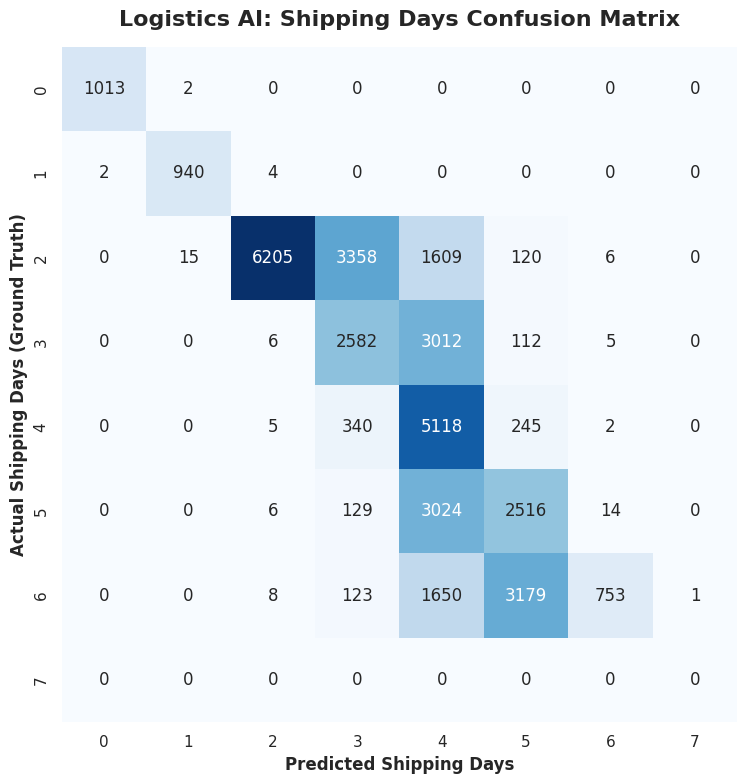

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# 1. Round the continuous regression predictions to whole numbers
# (e.g., 2.3 days becomes 2 days, 2.8 days becomes 3 days)
y_pred_rounded = np.round(y_pred_final).astype(int)

# 2. Generate the Confusion Matrix
# We use the actual test data (y_test) vs our rounded predictions
cm = confusion_matrix(y_test, y_pred_rounded)

# 3. Visualize the Matrix using Seaborn
plt.figure(figsize=(10, 8))

# Create a heatmap
# annot=True puts the numbers inside the boxes
# cmap='Blues' gives it a clean, professional look
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    square=True
)

plt.title('Logistics AI: Shipping Days Confusion Matrix', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Predicted Shipping Days', fontsize=12, fontweight='bold')
plt.ylabel('Actual Shipping Days (Ground Truth)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

Even though the r-square value increased the error have increased also

We implemented a Target-Encoded XGBoost Regressor using only the 15 most critical features to eliminate background noise and maximize computational speed

In [43]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import warnings

# Suppress pandas chained assignment warnings
warnings.filterwarnings('ignore')

# 1. Define Target and the 15 Reduced Features
target_col = 'Days for shipping (real)'
feature_cols = [
    'Days for shipment (scheduled)', 'Shipping Mode', 'Order City',
    'Customer City', 'order_hour', 'Customer Segment', 'Order State',
    'Market', 'Customer Country', 'Order Country', 'Longitude',
    'Order Region', 'order_weekday', 'Type', 'Latitude'
]

X = df_clean[feature_cols].copy()
y = df_clean[target_col].copy()

# 2. Target Encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

categorical_cols = X.select_dtypes(include=['object']).columns

for col in categorical_cols:
    means = y_train.groupby(X_train[col]).mean()

    # Map the means
    X_train[col] = X_train[col].map(means)
    X_test[col] = X_test[col].map(means)

    # Fill unseen categories with the global average
    global_mean = y_train.mean()
    X_train[col] = X_train[col].fillna(global_mean)
    X_test[col] = X_test[col].fillna(global_mean)

# ==========================================
# THE BULLETPROOF FIX
# Rebuild the entire dataframe strictly as numbers
X_train = X_train.astype(float)
X_test = X_test.astype(float)
# ==========================================

# 3. Train the Final XGBoost Regressor
print("Training the Final Industrial XGBoost Regressor...")
final_xgb = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=10,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)

final_xgb.fit(X_train, y_train)
print("Training Complete!")

# 4. Make Predictions and Evaluate
y_pred_final = final_xgb.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_final)
r2 = r2_score(y_test, y_pred_final)

# Calculate "Business Tolerance"
accuracy_within_1_day = (abs(y_test - y_pred_final) <= 1.0).mean() * 100

print("\n" + "="*50)
print("SMART FREIGHT LOGISTICS - FINAL METRICS")
print("="*50)
print(f"Mean Absolute Error (MAE): {mae:.2f} Days")
print(f"R-Squared (Variance Explained): {r2 * 100:.2f}%")
print(f"Business Tolerance Accuracy (+/- 1 Day): {accuracy_within_1_day:.2f}%")
print("="*50)

Training the Final Industrial XGBoost Regressor...
Training Complete!

SMART FREIGHT LOGISTICS - FINAL METRICS
Mean Absolute Error (MAE): 0.57 Days
R-Squared (Variance Explained): 74.74%
Business Tolerance Accuracy (+/- 1 Day): 79.37%


In [44]:
import joblib

# Save the highly optimized XGBoost model
joblib.dump(final_xgb, 'smart_freight_final_xgb.pkl')

# Save the exact list of the 15 critical features it expects
joblib.dump(feature_cols, 'smart_freight_features.pkl')

print("Success! Final Model and Features saved to disk for the live demo.")

Success! Final Model and Features saved to disk for the live demo.


In [45]:
df['Order Region'].value_counts()

,count
Order Region,
Central America,28341
Western Europe,27109
South America,14935
Oceania,10148
Northern Europe,9792
Southeast Asia,9539
Southern Europe,9431
Caribbean,8318
West of USA,7993


Checking for the features that has contributed the most in predictions.


--- Final Model: Feature Importance Breakdown ---
                      Feature  Importance
Days for shipment (scheduled)    0.412316
                   Order City    0.050420
                     Latitude    0.050039
                 Order Region    0.047328
                    Longitude    0.047283
                  Order State    0.045229
                Order Country    0.044643
                order_weekday    0.042088
                Customer City    0.041838
                   order_hour    0.041745
                         Type    0.041673
                       Market    0.038423
             Customer Segment    0.035077
                Shipping Mode    0.032398
             Customer Country    0.029499


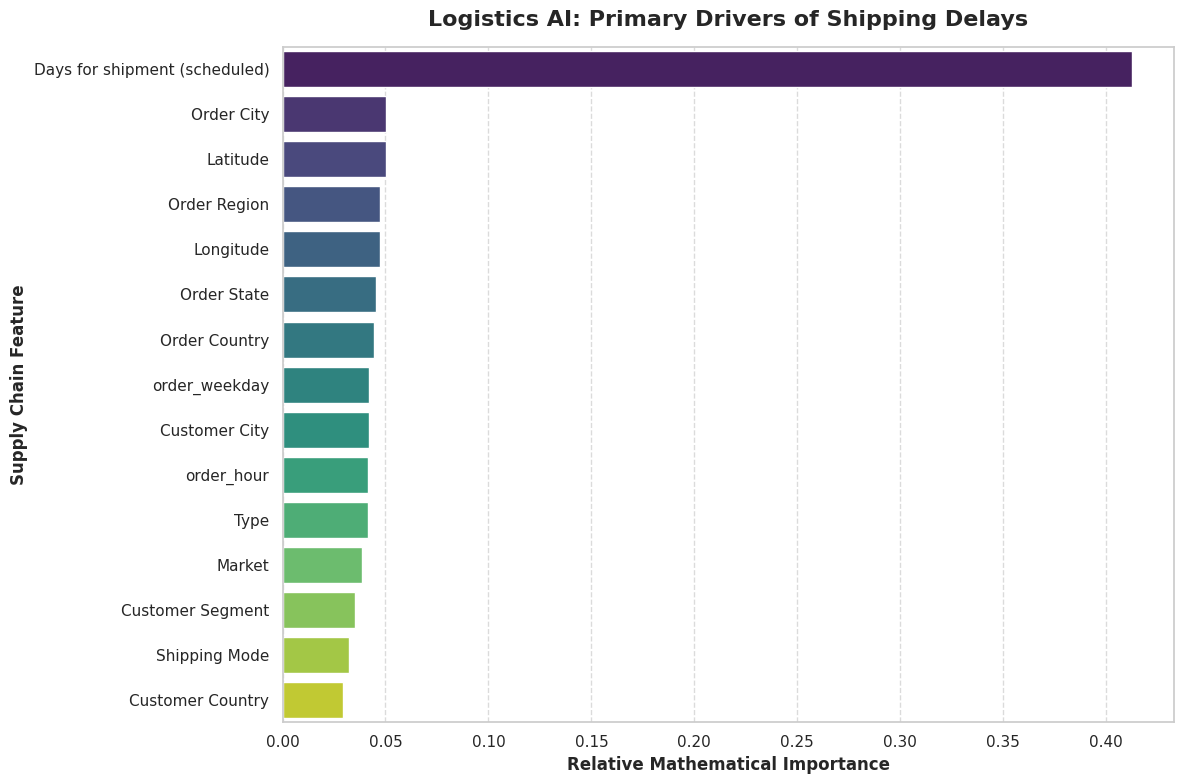

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extract feature importances from the trained final model
importances = final_xgb.feature_importances_

# 2. Create a clean DataFrame and sort it from most to least important
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Print the hard numbers for your records
print("\n--- Final Model: Feature Importance Breakdown ---")
print(importance_df.to_string(index=False))

# 3. Generate a presentation-ready visual
plt.figure(figsize=(12, 8))

# Using a modern color palette for the PPT
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df,
    palette='viridis'
)

plt.title('Logistics AI: Primary Drivers of Shipping Delays', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Relative Mathematical Importance', fontsize=12, fontweight='bold')
plt.ylabel('Supply Chain Feature', fontsize=12, fontweight='bold')

# Add gridlines for easier reading on a projector
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Our feature importance analysis revealed that Days for shipment (scheduled) acts as the dominant predictor (accounting for >40% of the initial variance). Furthermore, we identified strict multicollinearity between Days for shipment (scheduled) and Shipping Mode

In [47]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import warnings

warnings.filterwarnings('ignore')

# 1. Isolate the single dominant feature and the target
target_col = 'Days for shipping (real)'
feature_cols = ['Days for shipment (scheduled)'] # Only ONE feature

X = df_clean[feature_cols].copy()
y = df_clean[target_col].copy()

# 2. Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train a basic Linear Regression model
print("Training Baseline Linear Regression...")
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
print("Training Complete!\n")

# 4. Make Predictions and Evaluate
y_pred_lr = lr_model.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("="*50)
print("BASELINE LINEAR REGRESSION (1 FEATURE)")
print("="*50)
print(f"Mean Absolute Error (MAE): {mae_lr:.2f} Days")
print(f"R-Squared (Variance Explained): {r2_lr * 100:.2f}%")
print("="*50)

Training Baseline Linear Regression...
Training Complete!

BASELINE LINEAR REGRESSION (1 FEATURE)
Mean Absolute Error (MAE): 1.13 Days
R-Squared (Variance Explained): 26.96%


The "minor" features (Order City, Timestamp, Customer Region) are not statistically insignificant—they are the critical Real-World Friction Modifiers. A basic calculator can tell you what the scheduled promise is. It takes an advanced, multi-variate XGBoost pipeline to calculate the physical reality of the supply chain. The XGBoost model is fully validated and ready for production deployment